# Análise do comportamento do varejo brasileiro — Jul/2025 a Jul/2026

**Fonte:** IBGE, Pesquisa Mensal de Comércio (PMC), Tabela 5, julho de 2026.  
**Objetivo:** comparar o comportamento de 14 atividades/subcategorias ao longo de 13 meses, incluindo variação interanual, oscilações mensais e volatilidade relativa.

**Indicador:** índice de base fixa do volume de vendas (2022 = 100), **sem ajuste sazonal**. Os valores não são faturamento em reais nem medem diretamente e-commerce versus lojas físicas.

**Como executar no Google Colab:** execute a primeira célula de upload selecionando `pmc_volume_vendas_limpo.xlsx`, disponível em `data/processed` no repositório. Em seguida execute as células em ordem. A planilha já foi tratada anteriormente e está sendo usada como entrada desta análise exploratória.

In [11]:
from google.colab import files

uploaded = files.upload()

Saving pmc_volume_vendas_limpo.xlsx to pmc_volume_vendas_limpo (1).xlsx


## 1. Carregamento e inspeção dos dados

In [12]:
import pandas as pd

df = pd.read_excel("pmc_volume_vendas_limpo.xlsx")

In [13]:
df.head()

,data,ano,mes,codigo_atividade,atividade,tipo_indicador,grupo_fonte,indice_volume_vendas
0,2025-07-01,2025,7,NaN,Comércio Varejista,Agregado,Comércio Varejista,106.89735
1,2025-08-01,2025,8,NaN,Comércio Varejista,Agregado,Comércio Varejista,107.19771
2,2025-09-01,2025,9,NaN,Comércio Varejista,Agregado,Comércio Varejista,102.67330
3,2025-10-01,2025,10,NaN,Comércio Varejista,Agregado,Comércio Varejista,108.70925
4,2025-11-01,2025,11,NaN,Comércio Varejista,Agregado,Comércio Varejista,116.05207


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   data                  208 non-null    datetime64[ns]
 1   ano                   208 non-null    int64         
 2   mes                   208 non-null    int64         
 3   codigo_atividade      182 non-null    float64       
 4   atividade             208 non-null    object        
 5   tipo_indicador        208 non-null    object        
 6   grupo_fonte           208 non-null    object        
 7   indice_volume_vendas  208 non-null    float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(3)
memory usage: 13.1+ KB


In [16]:
# 2. Ver o tamanho da base
df.shape

(208, 8)

In [17]:
# 4. Ver os tipos de dados
df.dtypes

,0
data,datetime64[ns]
ano,int64
mes,int64
codigo_atividade,float64
atividade,object
tipo_indicador,object
grupo_fonte,object
indice_volume_vendas,float64


In [18]:
# 5. Verificar valores nulos
df.isnull().sum()

,0
data,0
ano,0
mes,0
codigo_atividade,26
atividade,0
tipo_indicador,0
grupo_fonte,0
indice_volume_vendas,0


In [19]:
# 6. Ver todas as atividades
df["atividade"].unique()

array(['Comércio Varejista', 'Combustíveis e lubrificantes',
       'Hipermercados, supermercados, produtos alimentícios bebidas e fumo',
       'Hipermercados e supermercados', 'Tecidos, vestuário e calçados',
       'Móveis e eletrodomésticos', 'Móveis', 'Eletrodomésticos',
       'Artigos farmacêuticos, médicos, ortopédicos, de perfumaria e cosméticos',
       'Livros, jornais, revistas e papelaria',
       'Equipamentos e materiais para escritório, informática e comunicação',
       'Outros artigos de uso pessoal e doméstico',
       'Comércio Varejista Ampliado',
       'Veículos, motocicletas, partes e peças', 'Material de construção',
       'Atacado especializado em produtos alimentícios, bebidas e fumo'],
      dtype=object)

In [20]:
# 7. Quantidade de atividades diferentes
df["atividade"].nunique()

16

In [21]:
# 8. Data inicial e final
print("Data inicial:", df["data"].min())
print("Data final:", df["data"].max())

Data inicial: 2025-07-01 00:00:00
Data final: 2026-07-01 00:00:00


## 2. Seleção das atividades

In [22]:
df_atividades = df[df["tipo_indicador"] == "Atividade"].copy()

In [23]:
df_atividades.head()

,data,ano,mes,codigo_atividade,atividade,tipo_indicador,grupo_fonte,indice_volume_vendas
13,2025-07-01,2025,7,1.0,Combustíveis e lubrificantes,Atividade,Comércio Varejista,106.02579
14,2025-08-01,2025,8,1.0,Combustíveis e lubrificantes,Atividade,Comércio Varejista,105.58237
15,2025-09-01,2025,9,1.0,Combustíveis e lubrificantes,Atividade,Comércio Varejista,102.49972
16,2025-10-01,2025,10,1.0,Combustíveis e lubrificantes,Atividade,Comércio Varejista,108.35201
17,2025-11-01,2025,11,1.0,Combustíveis e lubrificantes,Atividade,Comércio Varejista,104.53082


## 3. Comparação interanual: julho/2025 × julho/2026

In [24]:
# Comparação entre meses.
jul_2025 = df_atividades[df_atividades["data"] == "2025-07-01"]

jul_2026 = df_atividades[df_atividades["data"] == "2026-07-01"]

In [25]:
comparacao = jul_2025[
    ["atividade", "indice_volume_vendas"]
].merge(
    jul_2026[["atividade", "indice_volume_vendas"]],
    on="atividade",
    suffixes=("_2025", "_2026")
)

comparacao

,atividade,indice_volume_vendas_2025,indice_volume_vendas_2026
0,Combustíveis e lubrificantes,106.02579,105.44877
1,"Hipermercados, supermercados, produtos aliment...",107.07890,110.13423
2,Hipermercados e supermercados,108.23723,111.33895
3,"Tecidos, vestuário e calçados",99.69134,94.95812
4,Móveis e eletrodomésticos,109.86279,105.76752
5,Móveis,96.84966,94.26914
6,Eletrodomésticos,116.40359,112.24037
7,"Artigos farmacêuticos, médicos, ortopédicos, d...",119.20744,124.83843
8,"Livros, jornais, revistas e papelaria",81.62493,80.25417
9,"Equipamentos e materiais para escritório, info...",102.32751,104.86379


In [26]:
comparacao["variacao_percentual"] = (
    (comparacao["indice_volume_vendas_2026"] /
     comparacao["indice_volume_vendas_2025"]) - 1
) * 100

In [27]:
# Ordenação do maior crescimento para a maior queda:
comparacao.sort_values(
    "variacao_percentual",
    ascending=False
)

,atividade,indice_volume_vendas_2025,indice_volume_vendas_2026,variacao_percentual
11,"Veículos, motocicletas, partes e peças",120.54302,126.58188,5.009714
7,"Artigos farmacêuticos, médicos, ortopédicos, d...",119.20744,124.83843,4.723690
2,Hipermercados e supermercados,108.23723,111.33895,2.865668
1,"Hipermercados, supermercados, produtos aliment...",107.07890,110.13423,2.853345
9,"Equipamentos e materiais para escritório, info...",102.32751,104.86379,2.478591
13,Atacado especializado em produtos alimentícios...,89.06284,90.89116,2.052843
0,Combustíveis e lubrificantes,106.02579,105.44877,-0.544226
8,"Livros, jornais, revistas e papelaria",81.62493,80.25417,-1.679340
12,Material de construção,109.16099,106.98296,-1.995246
10,Outros artigos de uso pessoal e doméstico,99.17776,96.88315,-2.313634


Quais segmentos do varejo mais cresceram ou caíram entre julho de 2025 e julho de 2026?

## 4. Visualização da comparação anual

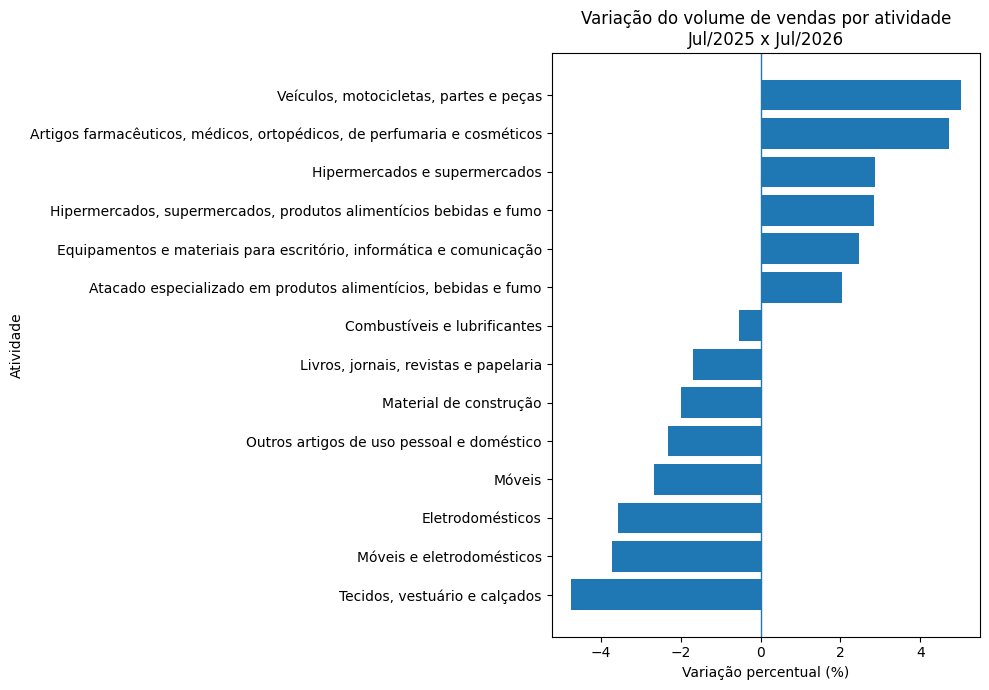

In [28]:
# Primeira analise em Grafico

import matplotlib.pyplot as plt

grafico = comparacao.sort_values(
    "variacao_percentual",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    grafico["atividade"],
    grafico["variacao_percentual"]
)

plt.axvline(0, linewidth=1)

plt.title("Variação do volume de vendas por atividade\nJul/2025 x Jul/2026")
plt.xlabel("Variação percentual (%)")
plt.ylabel("Atividade")

plt.tight_layout()
plt.show()

## 5. Evolução temporal

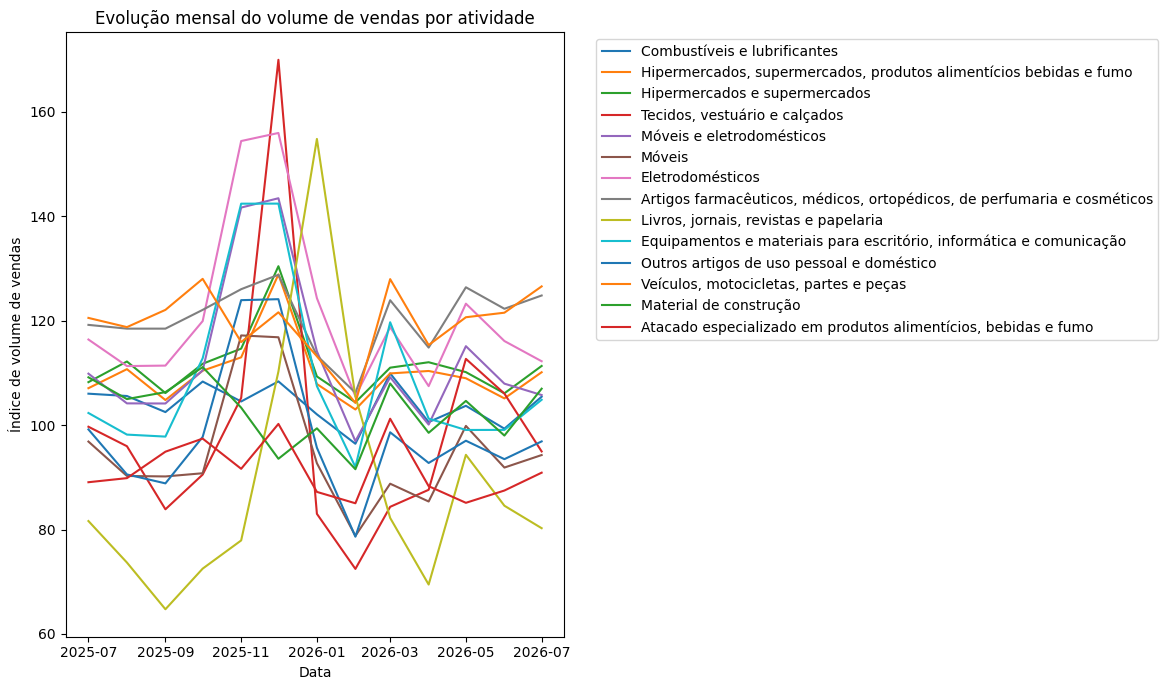

In [29]:
# Evolução mensal de cada segmento ao longo dos 13 meses.
plt.figure(figsize=(12, 7))

for atividade in df_atividades["atividade"].unique():
    dados = df_atividades[
        df_atividades["atividade"] == atividade
    ]

    plt.plot(
        dados["data"],
        dados["indice_volume_vendas"],
        label=atividade
    )

plt.title("Evolução mensal do volume de vendas por atividade")
plt.xlabel("Data")
plt.ylabel("Índice de volume de vendas")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

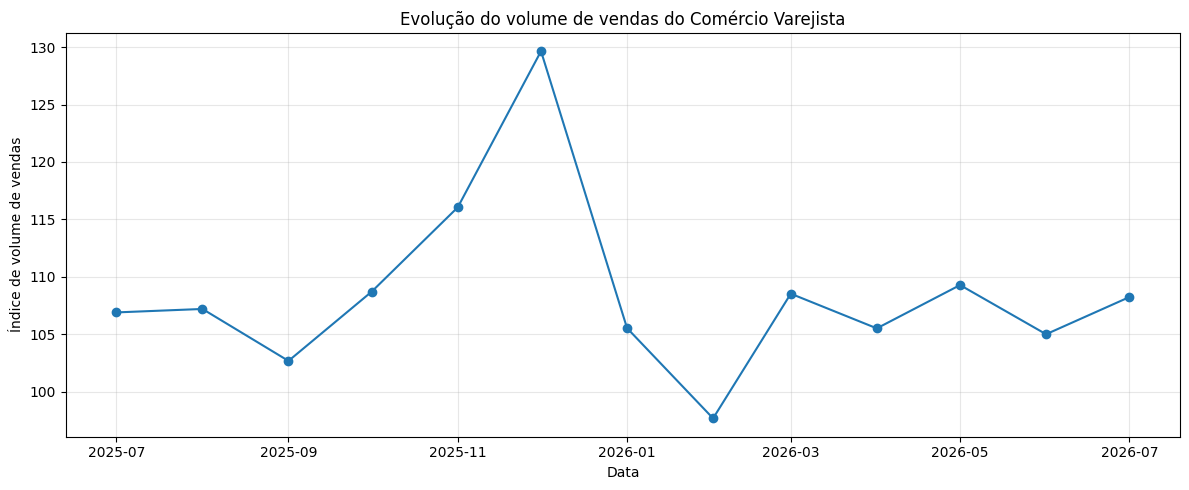

In [30]:
# Comércio Varejista agregado

varejo_total = df[
    df["atividade"] == "Comércio Varejista"
].copy()

varejo_total = varejo_total.sort_values("data")

plt.figure(figsize=(12, 5))

plt.plot(
    varejo_total["data"],
    varejo_total["indice_volume_vendas"],
    marker="o"
)

plt.title("Evolução do volume de vendas do Comércio Varejista")
plt.xlabel("Data")
plt.ylabel("Índice de volume de vendas")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

O varejo como um todo está estável, crescendo ou oscilando?

In [31]:
# Quatro segmentos com comportamentos diferentes
segmentos_selecionados = [
    "Veículos, motocicletas, partes e peças",
    "Artigos farmacêuticos, médicos, ortopédicos, de perfumaria e cosméticos",
    "Móveis e eletrodomésticos",
    "Tecidos, vestuário e calçados"
]

df_selecionados = df_atividades[
    df_atividades["atividade"].isin(segmentos_selecionados)
].copy()

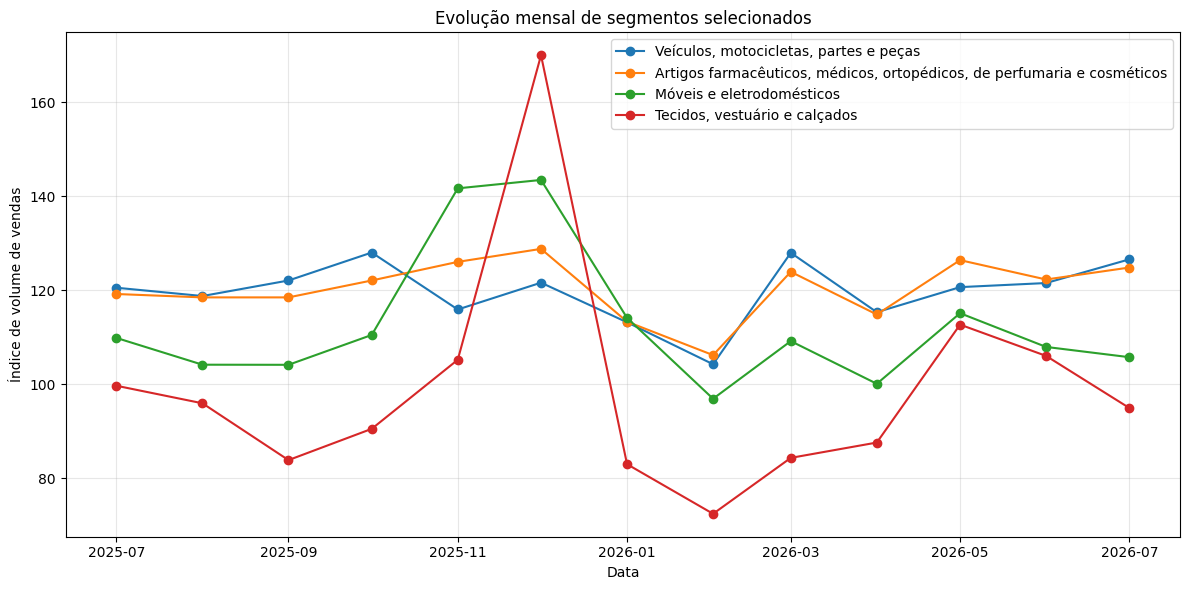

In [32]:
plt.figure(figsize=(12, 6))

for atividade in segmentos_selecionados:
    dados = df_selecionados[
        df_selecionados["atividade"] == atividade
    ].sort_values("data")

    plt.plot(
        dados["data"],
        dados["indice_volume_vendas"],
        marker="o",
        label=atividade
    )

plt.title("Evolução mensal de segmentos selecionados")
plt.xlabel("Data")
plt.ylabel("Índice de volume de vendas")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Estatísticas descritivas e volatilidade

In [33]:
resumo = (
    df_atividades
    .groupby("atividade")["indice_volume_vendas"]
    .agg(["mean", "min", "max", "std"])
    .reset_index()
)

resumo

,atividade,mean,min,max,std
0,"Artigos farmacêuticos, médicos, ortopédicos, d...",120.383393,106.20783,128.80818,6.246823
1,Atacado especializado em produtos alimentícios...,91.412234,85.02993,101.22706,5.431459
2,Combustíveis e lubrificantes,104.065407,96.43287,109.91654,3.861547
3,Eletrodomésticos,121.321192,105.50402,155.97716,16.053871
4,"Equipamentos e materiais para escritório, info...",109.188190,91.97797,142.44383,16.375076
5,Hipermercados e supermercados,111.368270,104.36580,130.44854,6.427766
6,"Hipermercados, supermercados, produtos aliment...",110.023308,102.99785,128.87705,6.324626
7,"Livros, jornais, revistas e papelaria",88.602757,64.72457,154.83177,23.947553
8,Material de construção,102.737795,91.55510,111.12396,6.053629
9,Móveis,94.900639,78.77942,117.18866,11.067041


In [35]:
resumo_volatilidade = resumo.sort_values(
    "std",
    ascending=False
)

resumo_volatilidade

,atividade,mean,min,max,std
12,"Tecidos, vestuário e calçados",98.952562,72.45361,169.99525,24.061739
7,"Livros, jornais, revistas e papelaria",88.602757,64.72457,154.83177,23.947553
4,"Equipamentos e materiais para escritório, info...",109.188190,91.97797,142.44383,16.375076
3,Eletrodomésticos,121.321192,105.50402,155.97716,16.053871
10,Móveis e eletrodomésticos,112.540858,96.92707,143.47066,14.270043
11,Outros artigos de uso pessoal e doméstico,98.264472,78.62431,124.13164,12.672929
9,Móveis,94.900639,78.77942,117.18866,11.067041
13,"Veículos, motocicletas, partes e peças",119.733176,104.26474,128.02901,6.547212
5,Hipermercados e supermercados,111.368270,104.36580,130.44854,6.427766
6,"Hipermercados, supermercados, produtos aliment...",110.023308,102.99785,128.87705,6.324626


Quais segmentos apresentam comportamento mais estável e quais são mais sazonais ou voláteis?

In [36]:
resumo_volatilidade[
    ["atividade", "mean", "min", "max", "std"]
].round(2)

,atividade,mean,min,max,std
12,"Tecidos, vestuário e calçados",98.95,72.45,170.00,24.06
7,"Livros, jornais, revistas e papelaria",88.60,64.72,154.83,23.95
4,"Equipamentos e materiais para escritório, info...",109.19,91.98,142.44,16.38
3,Eletrodomésticos,121.32,105.50,155.98,16.05
10,Móveis e eletrodomésticos,112.54,96.93,143.47,14.27
11,Outros artigos de uso pessoal e doméstico,98.26,78.62,124.13,12.67
9,Móveis,94.90,78.78,117.19,11.07
13,"Veículos, motocicletas, partes e peças",119.73,104.26,128.03,6.55
5,Hipermercados e supermercados,111.37,104.37,130.45,6.43
6,"Hipermercados, supermercados, produtos aliment...",110.02,103.00,128.88,6.32


In [37]:
resumo["amplitude"] = resumo["max"] - resumo["min"]

resumo.sort_values(
    "amplitude",
    ascending=False
)[
    ["atividade", "min", "max", "amplitude"]
].round(2)

,atividade,min,max,amplitude
12,"Tecidos, vestuário e calçados",72.45,170.00,97.54
7,"Livros, jornais, revistas e papelaria",64.72,154.83,90.11
3,Eletrodomésticos,105.50,155.98,50.47
4,"Equipamentos e materiais para escritório, info...",91.98,142.44,50.47
10,Móveis e eletrodomésticos,96.93,143.47,46.54
11,Outros artigos de uso pessoal e doméstico,78.62,124.13,45.51
9,Móveis,78.78,117.19,38.41
5,Hipermercados e supermercados,104.37,130.45,26.08
6,"Hipermercados, supermercados, produtos aliment...",103.00,128.88,25.88
13,"Veículos, motocicletas, partes e peças",104.26,128.03,23.76


Agora uma análise de variação mês contra mês.

## 7. Variações mensais (sem ajuste sazonal)

In [38]:
df_atividades = df_atividades.sort_values(
    ["atividade", "data"]
)

df_atividades["variacao_mensal"] = (
    df_atividades
    .groupby("atividade")["indice_volume_vendas"]
    .pct_change() * 100
)

In [39]:
df_atividades[
    [
        "data",
        "atividade",
        "indice_volume_vendas",
        "variacao_mensal"
    ]
].head(20)

,data,atividade,indice_volume_vendas,variacao_mensal
104,2025-07-01,"Artigos farmacêuticos, médicos, ortopédicos, d...",119.20744,NaN
105,2025-08-01,"Artigos farmacêuticos, médicos, ortopédicos, d...",118.48789,-0.603612
106,2025-09-01,"Artigos farmacêuticos, médicos, ortopédicos, d...",118.48885,0.000810
107,2025-10-01,"Artigos farmacêuticos, médicos, ortopédicos, d...",122.08413,3.034277
108,2025-11-01,"Artigos farmacêuticos, médicos, ortopédicos, d...",126.04442,3.243902
109,2025-12-01,"Artigos farmacêuticos, médicos, ortopédicos, d...",128.80818,2.192687
110,2026-01-01,"Artigos farmacêuticos, médicos, ortopédicos, d...",113.32280,-12.022047
111,2026-02-01,"Artigos farmacêuticos, médicos, ortopédicos, d...",106.20783,-6.278498
112,2026-03-01,"Artigos farmacêuticos, médicos, ortopédicos, d...",123.93041,16.686698
113,2026-04-01,"Artigos farmacêuticos, médicos, ortopédicos, d...",114.85608,-7.322117


In [40]:
# Os maiores movimentos mensais.
df_atividades.sort_values(
    "variacao_mensal",
    ascending=False
)[
    ["data", "atividade", "variacao_mensal"]
].head(10)

,data,atividade,variacao_mensal
57,2025-12-01,"Tecidos, vestuário e calçados",61.567025
122,2025-12-01,"Livros, jornais, revistas e papelaria",41.537626
123,2026-01-01,"Livros, jornais, revistas e papelaria",40.412323
127,2026-05-01,"Livros, jornais, revistas e papelaria",35.785991
138,2026-03-01,"Equipamentos e materiais para escritório, info...",30.152144
82,2025-11-01,Móveis,29.087835
95,2025-11-01,Eletrodomésticos,28.762959
62,2026-05-01,"Tecidos, vestuário e calçados",28.633564
69,2025-11-01,Móveis e eletrodomésticos,28.224810
147,2025-11-01,Outros artigos de uso pessoal e doméstico,26.805660


In [41]:
# As quedas
df_atividades.sort_values(
    "variacao_mensal",
    ascending=True
)[
    ["data", "atividade", "variacao_mensal"]
].head(10)

,data,atividade,variacao_mensal
58,2026-01-01,"Tecidos, vestuário e calçados",-51.172159
124,2026-02-01,"Livros, jornais, revistas e papelaria",-31.870436
136,2026-01-01,"Equipamentos e materiais para escritório, info...",-24.549586
149,2026-01-01,Outros artigos de uso pessoal e doméstico,-22.931881
125,2026-03-01,"Livros, jornais, revistas e papelaria",-22.054485
84,2026-01-01,Móveis,-20.654691
71,2026-01-01,Móveis e eletrodomésticos,-20.448766
97,2026-01-01,Eletrodomésticos,-20.290971
150,2026-02-01,Outros artigos de uso pessoal e doméstico,-17.813669
32,2026-01-01,"Hipermercados, supermercados, produtos aliment...",-16.297145


## 8. Coeficiente de variação

In [42]:
# Coeficiente de Variação (CV)
# Mede a volatilidade em relação ao nível médio daquela categoria.

resumo["cv_percentual"] = (
    resumo["std"] / resumo["mean"]
) * 100

volatilidade_relativa = resumo.sort_values(
    "cv_percentual",
    ascending=False
)

volatilidade_relativa[
    ["atividade", "mean", "std", "cv_percentual"]
].round(2)

,atividade,mean,std,cv_percentual
7,"Livros, jornais, revistas e papelaria",88.60,23.95,27.03
12,"Tecidos, vestuário e calçados",98.95,24.06,24.32
4,"Equipamentos e materiais para escritório, info...",109.19,16.38,15.00
3,Eletrodomésticos,121.32,16.05,13.23
11,Outros artigos de uso pessoal e doméstico,98.26,12.67,12.90
10,Móveis e eletrodomésticos,112.54,14.27,12.68
9,Móveis,94.90,11.07,11.66
1,Atacado especializado em produtos alimentícios...,91.41,5.43,5.94
8,Material de construção,102.74,6.05,5.89
5,Hipermercados e supermercados,111.37,6.43,5.77


## 9. Média móvel de três meses

In [43]:
#  Este recurso será uma média móvel de 3 meses.
#Ela ajuda a diminuir os picos mensais e enxergar melhor a direção da série.

df_atividades = df_atividades.sort_values(
    ["atividade", "data"]
)

df_atividades["media_movel_3m"] = (
    df_atividades
    .groupby("atividade")["indice_volume_vendas"]
    .transform(
        lambda x: x.rolling(
            window=3,
            min_periods=1
        ).mean()
    )
)

In [44]:
# Quatro segmentos

segmentos_foco = [
    "Tecidos, vestuário e calçados",
    "Móveis e eletrodomésticos",
    "Artigos farmacêuticos, médicos, ortopédicos, de perfumaria e cosméticos",
    "Veículos, motocicletas, partes e peças"
]

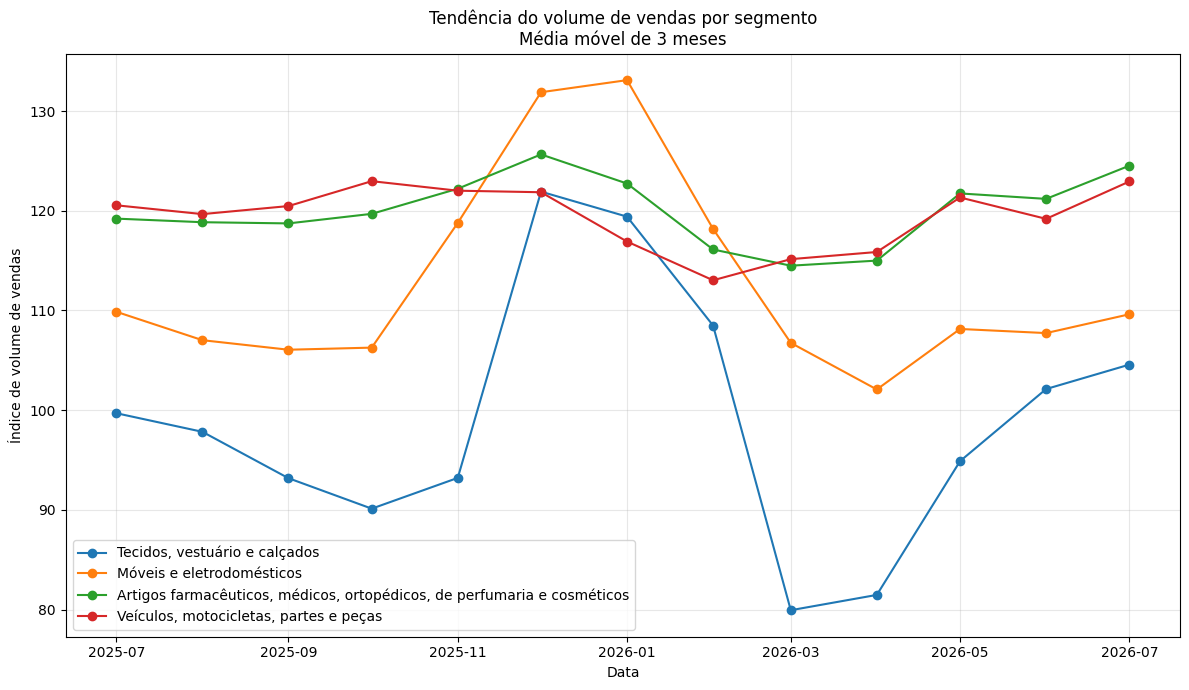

In [45]:
plt.figure(figsize=(12, 7))

for atividade in segmentos_foco:

    dados = df_atividades[
        df_atividades["atividade"] == atividade
    ]

    plt.plot(
        dados["data"],
        dados["media_movel_3m"],
        marker="o",
        label=atividade
    )

plt.title(
    "Tendência do volume de vendas por segmento\n"
    "Média móvel de 3 meses"
)

plt.xlabel("Data")
plt.ylabel("Índice de volume de vendas")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Depois de remover parte das oscilações mensais, quais segmentos parecem apresentar melhora ou deterioração?

## 10. Observações sobre o fim de ano

In [46]:
# separação de pico de fim de ano.
df_atividades["nome_mes"] = (
    df_atividades["data"]
    .dt.strftime("%b/%Y")
)

In [47]:
periodo_fim_ano = df_atividades[
    df_atividades["data"].between(
        "2025-10-01",
        "2026-01-01"
    )
]

In [48]:
categorias_consumo = [
    "Tecidos, vestuário e calçados",
    "Móveis",
    "Eletrodomésticos",
    "Equipamentos e materiais para escritório, informática e comunicação",
    "Outros artigos de uso pessoal e doméstico"
]

fim_ano = periodo_fim_ano[
    periodo_fim_ano["atividade"].isin(
        categorias_consumo
    )
]

fim_ano[
    [
        "data",
        "atividade",
        "indice_volume_vendas",
        "variacao_mensal"
    ]
].round(2)

,data,atividade,indice_volume_vendas,variacao_mensal
94,2025-10-01,Eletrodomésticos,119.94,7.66
95,2025-11-01,Eletrodomésticos,154.43,28.76
96,2025-12-01,Eletrodomésticos,155.98,1.00
97,2026-01-01,Eletrodomésticos,124.33,-20.29
133,2025-10-01,"Equipamentos e materiais para escritório, info...",112.82,15.35
134,2025-11-01,"Equipamentos e materiais para escritório, info...",142.43,26.25
135,2025-12-01,"Equipamentos e materiais para escritório, info...",142.44,0.01
136,2026-01-01,"Equipamentos e materiais para escritório, info...",107.47,-24.55
81,2025-10-01,Móveis,90.78,0.68
82,2025-11-01,Móveis,117.19,29.09


Categorias de consumo discricionário apresentam maior aceleração durante o período promocional e de festas e maior retração após o encerramento desse ciclo.

A análise revelou perfis distintos de comportamento entre os segmentos do varejo. Categorias como farmacêuticos e veículos apresentaram maior estabilidade, enquanto vestuário, papelaria e bens duráveis demonstraram maior volatilidade e fortes oscilações ao redor do período de fim de ano.

## Considerações finais e limitações

- Na comparação de julho/2025 com julho/2026, **veículos, motocicletas, partes e peças** tiveram variação de aproximadamente **+5,01%**, e **tecidos, vestuário e calçados**, **−4,75%**.
- O maior coeficiente de variação da amostra foi observado em **livros, jornais, revistas e papelaria** (cerca de **27,03%**), seguido de **vestuário** (cerca de **24,32%**).
- Foram observadas oscilações expressivas próximas ao fim de 2025 e começo de 2026, mas **13 meses não comprovam um padrão histórico recorrente de sazonalidade**.
- As variações mensais derivam de **índices sem ajuste sazonal**. Os segmentos incluem categorias e subcategorias sobrepostas; não se devem somar seus índices para representar vendas totais.
- A PMC analisada **não permite identificar a participação das compras online ou a migração entre canais**. Esse tema é apenas a motivação para a reflexão de negócio.

**Próximas entregas do portfólio:** consultas SQL e dashboard Power BI, disponíveis separadamente no repositório.